<a href="https://colab.research.google.com/github/Jhanasri-thota/DLAC_2520090121/blob/main/visionport_Advanced_week1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
VISIONPORT INITIALIZING...

SYSTEM INFORMATION
PyTorch: 2.14.1+cpu
CUDA: False
GPU: Not available. Using CPU instead.

Loading YOLO26 Large...
Model Loaded Successfully!

UPLOAD A TRAFFIC IMAGE FOR TASK 2/3


Saving images (3).jpg to images (3).jpg
Image: images (3).jpg
Resolution: 554 x 554


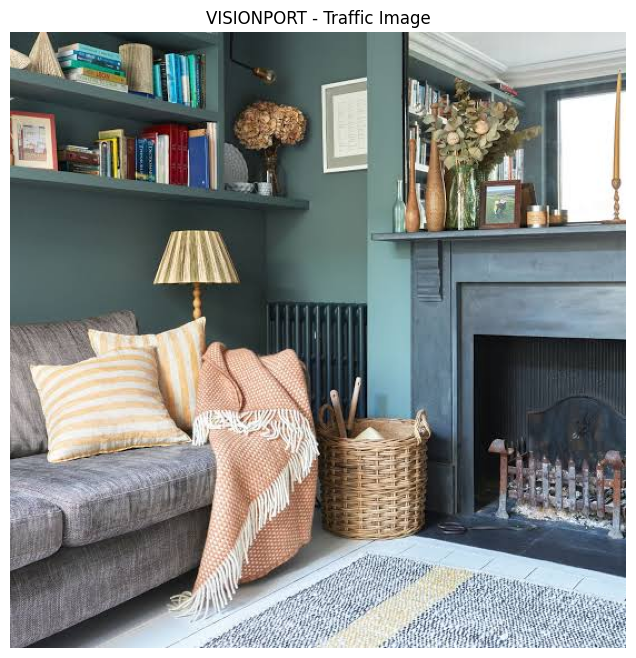


IMAGE DETECTION REPORT
vase : 5
book : 20
couch : 1
bottle : 1
Total Objects: 27


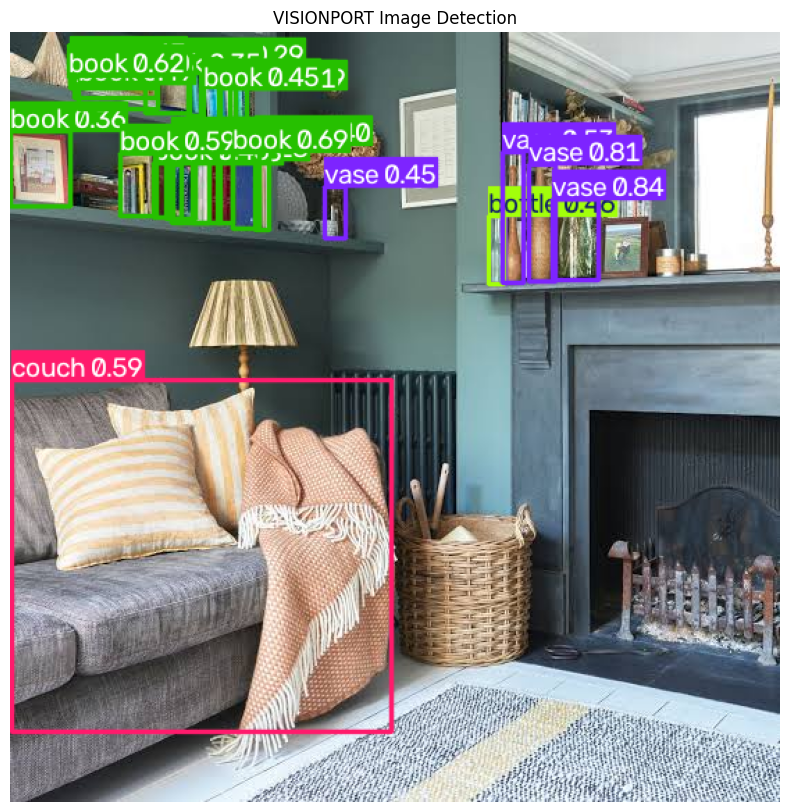


UPLOAD A TRAFFIC VIDEO FOR TASKS 4-20


Saving (17) MUMBAI TRAFFIC _ INDIA - YouTube - Google Chrome 2026-11-16 10-28-37.mp4 to (17) MUMBAI TRAFFIC _ INDIA - YouTube - Google Chrome 2026-11-16 10-28-37.mp4

VIDEO INFORMATION
Width: 1920
Height: 1020
FPS: 26.121501260725235
Total Frames: 624
Duration: 23.89 seconds

VISIONPORT VIDEO ANALYSIS STARTED
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.18 environment at: /usr
Resolved 2 packages in 339ms
Prepared 1 package in 642ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Processed 100/624 frames
Processed 200/624 frames
Processed 300/624 frames
Processed 400/624 frames
Processed 500/624 frames
Processed 600/624 frames

VIDEO ANALYSIS COMPLETED!
Frames Extracted: 10

VEHICLE COUNT REPORT
Car : 107
Motorcycle : 33
Truck : 21
Bus : 30
Unique Tracked Vehicles: 191

TRAFFIC DENSITY REPORT
Average Vehi

,Vehicle Type,Unique Count
0,Car,107
1,Motorcycle,33
2,Truck,21
3,Bus,30


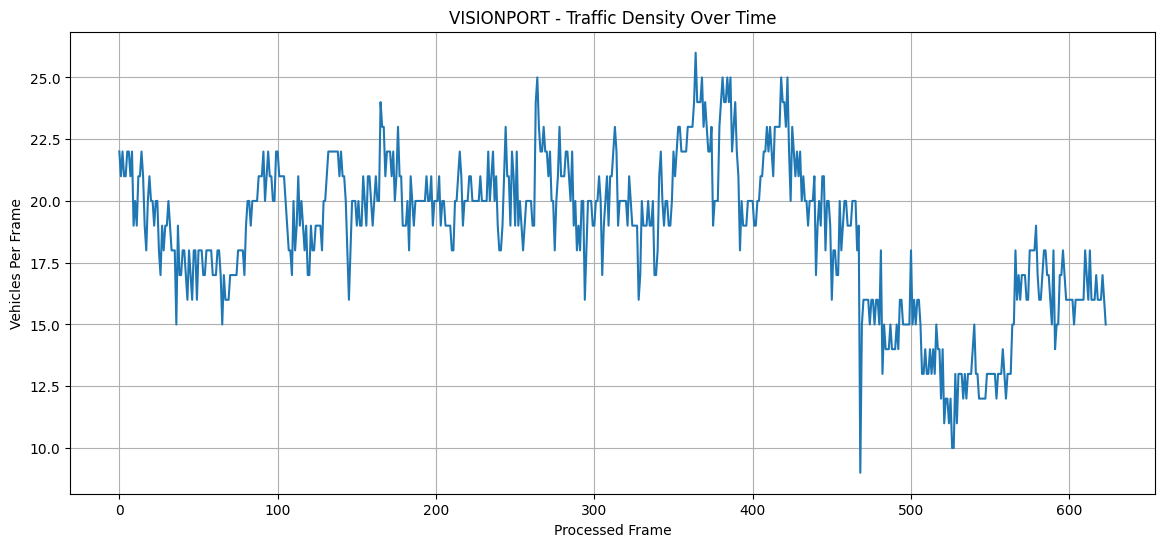


VISIONPORT - ALL 20 TASKS PROCESSED
Image Detection: 27
Unique Tracked Vehicles: 191
Entry Count: 0
Exit Count: 22
Wrong-Way IDs: 58
Possible Wrong Turns: 94
Possible Illegal Parking: 0
Output Video: /content/VISIONPORT_Results/Traffic_Analysis.mp4

VISIONPORT PROCESSED VIDEO
Buffered data was truncated after reaching the output size limit.

In [ ]:
# ================================================================
# VISIONPORT
# INTELLIGENT VEHICLE DETECTION AND TRAFFIC MONITORING
# COMPLETE 20-TASK IMPLEMENTATION
# YOLO26L + OPENCV + BYTETRACK + PYTORCH
# ================================================================

# ===================== 1. INSTALLATION ===========================

!pip install -q ultralytics opencv-python matplotlib pandas==2.2.3

# ===================== 2. IMPORT LIBRARIES =======================

import os
import cv2
import torch
import time
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter, defaultdict, deque
from ultralytics import YOLO
from google.colab import files
from IPython.display import display, Video

print("VISIONPORT INITIALIZING...")

# ===================== 3. GPU CHECK ==============================

print("\nSYSTEM INFORMATION")

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("GPU: Not available. Using CPU instead.")

# ===================== 4. LOAD YOLO MODEL ========================

print("\nLoading YOLO26 Large...")

model = YOLO("yolo26l.pt")

print("Model Loaded Successfully!")

# COCO classes
PERSON = 0
BICYCLE = 1
CAR = 2
MOTORCYCLE = 3
BUS = 5
TRAIN = 6
TRUCK = 7
TRAFFIC_LIGHT = 9

VEHICLE_CLASSES = [1, 2, 3, 5, 6, 7]

VEHICLE_NAMES = {
    1: "Bicycle",
    2: "Car",
    3: "Motorcycle",
    5: "Bus",
    6: "Train",
    7: "Truck"
}

# ===================== 5. CONFIGURATION ==========================

# Adjust these according to your video.
CONFIDENCE = 0.25
IMAGE_SIZE = 960

# Speed estimation:
# Set this after calibrating the camera.
# Example: 20 pixels = 1 meter.
PIXELS_PER_METER = None

# Entry and exit line positions (percentage of frame height).
ENTRY_LINE_RATIO = 0.25
EXIT_LINE_RATIO = 0.75

# Expected traffic direction:
# "down" or "up"
EXPECTED_DIRECTION = "down"

# Restricted parking zone as polygon points (percentages).
# Example: [(10, 60), (40, 60), (40, 90), (10, 90)]
# Empty list means no restricted zone configured.
RESTRICTED_ZONE = []

# Parking threshold in seconds.
PARKING_THRESHOLD = 10

# Congestion threshold.
LOW_TRAFFIC = 5
HIGH_TRAFFIC = 15

# ===================== 6. UPLOAD TRAFFIC IMAGE ===================

print("\nUPLOAD A TRAFFIC IMAGE FOR TASK 2/3")

uploaded_image = files.upload()

if not uploaded_image:
    raise ValueError("Please upload a traffic image.")

image_path = next(iter(uploaded_image))

image = cv2.imread(image_path)

if image is None:
    raise ValueError("Invalid image.")

height, width = image.shape[:2]

print("Image:", image_path)

print("Resolution:", width, "x", height)

# ===================== 7. DISPLAY IMAGE ==========================

plt.figure(figsize=(14, 8))

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

plt.title("VISIONPORT - Traffic Image")

plt.axis("off")

plt.show()

# ===================== 8. IMAGE OBJECT DETECTION =================

image_result = model.predict(
    source=image,
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE,
    device=DEVICE,
    max_det=1000,
    verbose=False
)[0]

image_annotated = image_result.plot()

print("\nIMAGE DETECTION REPORT")

image_counts = Counter(
    model.names[int(box.cls[0])]
    for box in image_result.boxes
)

for name, count in image_counts.items():
    print(name, ":", count)

print("Total Objects:", len(image_result.boxes))

plt.figure(figsize=(16, 10))

plt.imshow(cv2.cvtColor(image_annotated, cv2.COLOR_BGR2RGB))

plt.title("VISIONPORT Image Detection")

plt.axis("off")

plt.show()

# ===================== 9. UPLOAD TRAFFIC VIDEO ===================

print("\nUPLOAD A TRAFFIC VIDEO FOR TASKS 4-20")

uploaded_video = files.upload()

if not uploaded_video:
    raise ValueError("Please upload a traffic video.")

video_path = next(iter(uploaded_video))

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("Unable to open video.")

fps = cap.get(cv2.CAP_PROP_FPS)

if not np.isfinite(fps) or fps <= 0:
    fps = 25.0

video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("\nVIDEO INFORMATION")
print("Width:", video_width)
print("Height:", video_height)
print("FPS:", fps)
print("Total Frames:", total_frames)
print("Duration:", round(total_frames / fps, 2), "seconds")

# ===================== 10. FRAME EXTRACTION ======================

os.makedirs("/content/VISIONPORT_Frames", exist_ok=True)

# ===================== 11. TRACKING INITIALIZATION ===============

vehicle_tracks = defaultdict(lambda: deque(maxlen=30))

vehicle_first_seen = {}
vehicle_last_seen = {}

vehicle_counts = Counter()

entry_count = 0
exit_count = 0

wrong_way_ids = set()
wrong_turn_ids = set()
illegal_parking_ids = set()

vehicle_speeds = {}

frame_density = []

congestion_frames = 0

signal_status_history = []

frame_number = 0

# ===================== 12. HELPER FUNCTIONS ======================

def get_center(box):

    x1, y1, x2, y2 = box

    return (
        int((x1 + x2) / 2),
        int((y1 + y2) / 2)
    )


def detect_signal_state(frame, box):

    x1, y1, x2, y2 = map(int, box)

    crop = frame[
        max(0, y1):max(0, y2),
        max(0, x1):max(0, x2)
    ]

    if crop.size == 0:
        return "Unknown"

    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)

    red = cv2.inRange(
        hsv, np.array([0, 100, 100]),
        np.array([10, 255, 255])
    )

    red2 = cv2.inRange(
        hsv, np.array([160, 100, 100]),
        np.array([180, 255, 255])
    )

    yellow = cv2.inRange(
        hsv, np.array([15, 100, 100]),
        np.array([35, 255, 255])
    )

    green = cv2.inRange(
        hsv, np.array([40, 70, 70]),
        np.array([90, 255, 255])
    )

    values = {
        "Red": cv2.countNonZero(red) + cv2.countNonZero(red2),
        "Yellow": cv2.countNonZero(yellow),
        "Green": cv2.countNonZero(green)
    }

    state = max(values, key=values.get)

    if values[state] < 3:
        return "Unknown"

    return state


def point_inside_polygon(point, polygon):

    if len(polygon) < 3:
        return False

    return cv2.pointPolygonTest(
        np.array(polygon, dtype=np.int32),
        point,
        False
    ) >= 0


# ===================== 13. VIDEO PROCESSING ======================

print("\nVISIONPORT VIDEO ANALYSIS STARTED")

os.makedirs("/content/VISIONPORT_Results", exist_ok=True)

output_video = "/content/VISIONPORT_Results/Traffic_Analysis.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    output_video,
    fourcc,
    fps,
    (video_width, video_height)
)

if not writer.isOpened():
    raise RuntimeError("Unable to create output video.")

# Process every frame.
# For very long videos, processing can take considerable time.

while True:

    ret, frame = cap.read()

    if not ret:
        break

    frame_number += 1

    current_time = frame_number / fps

    # Save first few frames for Task 5.
    if frame_number % max(1, int(fps)) == 0 and frame_number <= fps * 10:

        cv2.imwrite(
            f"/content/VISIONPORT_Frames/frame_{frame_number}.jpg",
            frame
        )

    # VEHICLE DETECTION AND TRACKING

    results = model.track(
        source=frame,
        persist=True,
        tracker="bytetrack.yaml",
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE,
        classes=[PERSON] + VEHICLE_CLASSES + [TRAFFIC_LIGHT],
        device=DEVICE,
        max_det=1000,
        verbose=False
    )

    result = results[0]

    annotated = frame.copy()

    current_vehicle_count = 0

    current_person_boxes = []

    current_motorcycle_boxes = []

    signal_states = []

    active_frame_track_ids = []

    # Process detections.

    if result.boxes is not None and len(result.boxes) > 0:

        boxes = result.boxes

        for box in boxes:

            class_id = int(box.cls[0])

            confidence = float(box.conf[0])

            x1, y1, x2, y2 = map(
                int,
                box.xyxy[0].tolist()
            )

            center = get_center((x1, y1, x2, y2))

            # PERSON DETECTION

            if class_id == PERSON:

                current_person_boxes.append(
                    (x1, y1, x2, y2, center)
                )

            # TRAFFIC LIGHT DETECTION

            if class_id == TRAFFIC_LIGHT:

                state = detect_signal_state(
                    frame,
                    (x1, y1, x2, y2)
                )

                signal_states.append(state)

                cv2.putText(
                    annotated,
                    "Signal: " + state,
                    (x1, max(20, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 255, 255),
                    2
                )

            # VEHICLE DETECTION

            if class_id in VEHICLE_CLASSES:

                current_vehicle_count += 1

                vehicle_name = VEHICLE_NAMES[class_id]

                track_id = None

                if box.id is not None:
                    track_id = int(box.id[0])
                    active_frame_track_ids.append(track_id)

                if class_id == MOTORCYCLE:

                    current_motorcycle_boxes.append(
                        (x1, y1, x2, y2)
                    )

                label = vehicle_name

                if track_id is not None:

                    label += f" ID:{track_id}"

                    if track_id not in vehicle_first_seen:

                        vehicle_first_seen[track_id] = current_time

                        vehicle_counts[vehicle_name] += 1

                    vehicle_last_seen[track_id] = current_time

                    track = vehicle_tracks[track_id]

                    track.append((center[0], center[1], current_time))

                    # ENTRY AND EXIT COUNTING

                    previous_y = (
                        track[-2][1] if len(track) >= 2 else center[1]
                    )

                    current_y = center[1]

                    entry_line = int(video_height * ENTRY_LINE_RATIO)

                    exit_line = int(video_height * EXIT_LINE_RATIO)

                    if len(track) >= 2:

                        if previous_y < entry_line <= current_y:

                            entry_count += 1

                        if previous_y < exit_line <= current_y:

                            exit_count += 1

                    # WRONG-WAY DETECTION

                    displacement = current_y - previous_y

                    if EXPECTED_DIRECTION == "down" and displacement < -5:

                        wrong_way_ids.add(track_id)

                    elif EXPECTED_DIRECTION == "up" and displacement > 5:

                        wrong_way_ids.add(track_id)

                    # WRONG TURN APPROXIMATION

                    if len(track) >= 8:

                        points = np.array(
                            [(p[0], p[1]) for p in track],
                            dtype=float
                        )

                        vectors = np.diff(points, axis=0)

                        angles = np.arctan2(
                            vectors[:, 1],
                            vectors[:, 0]
                        )

                        angle_changes = np.diff(angles)

                        angle_changes = (
                            angle_changes + np.pi
                        ) % (2 * np.pi) - np.pi

                        total_turn = abs(
                            np.sum(angle_changes)
                        )

                        if total_turn > np.pi / 2:

                            wrong_turn_ids.add(track_id)

                    # APPROXIMATE SPEED ESTIMATION

                    if (
                        PIXELS_PER_METER is not None
                        and len(track) >= 2
                    ):

                        x_old, y_old, t_old = track[-2]

                        distance_pixels = math.dist(
                            (center[0], center[1]),
                            (x_old, y_old)
                        )

                        elapsed = current_time - t_old

                        if elapsed > 0:

                            speed = (
                                distance_pixels /
                                PIXELS_PER_METER /
                                elapsed
                            ) * 3.6

                            vehicle_speeds[track_id] = round(
                                speed, 2
                            )

                            label += f" {speed:.1f} km/h"

                    # PARKING DETECTION

                    if RESTRICTED_ZONE:

                        polygon = [
                            (
                                int(x * video_width / 100),
                                int(y * video_height / 100)
                            )
                            for x, y in RESTRICTED_ZONE
                        ]

                        if point_inside_polygon(center, polygon):

                            stationary = False

                            if len(track) >= 5:

                                first = track[0]

                                displacement = math.dist(
                                    center,
                                    (first[0], first[1])
                                )

                                stationary = displacement < 10

                            if stationary:

                                parked_time = (
                                    current_time -
                                    vehicle_first_seen[track_id]
                                )

                                if parked_time >= PARKING_THRESHOLD:

                                    illegal_parking_ids.add(track_id)

                            cv2.polylines(
                                annotated,
                                [np.array(polygon)],
                                True,
                                (255, 0, 255),
                                2
                            )

                # DRAW VEHICLE BOX

                cv2.rectangle(
                    annotated,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                cv2.putText(
                    annotated,
                    f"{label} {confidence:.2f}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    (0, 255, 0),
                    2
                )

            # DRAW PERSON BOX

            elif class_id == PERSON:

                cv2.rectangle(
                    annotated,
                    (x1, y1),
                    (x2, y2),
                    (255, 100, 0),
                    2
                )

                cv2.putText(
                    annotated,
                    f"Person {confidence:.2f}",
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (255, 100, 0),
                    2
                )

    # ================= TRIPLE RIDING APPROXIMATION =================

    triple_riding_count = 0

    for mx1, my1, mx2, my2 in current_motorcycle_boxes:

        rider_count = 0

        for px1, py1, px2, py2, pcenter in current_person_boxes:

            if (
                mx1 - 15 <= pcenter[0] <= mx2 + 15
                and my1 - 0.5 * (my2 - my1) <= pcenter[1] <= my2 + 15
            ):

                rider_count += 1

        if rider_count >= 3:

            triple_riding_count += 1

            cv2.putText(
                annotated,
                "POSSIBLE TRIPLE RIDING",
                (mx1, max(20, my1 - 25)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 0, 255),
                2
                )

    # ================= TRAFFIC DENSITY =============================

    frame_density.append(current_vehicle_count)

    if current_vehicle_count <= LOW_TRAFFIC:

        density = "LOW"

    elif current_vehicle_count <= HIGH_TRAFFIC:

        density = "MEDIUM"

    else:

        density = "HIGH"

    if density == "HIGH":

        congestion_frames += 1

    # ================= TRAFFIC SIGNAL STATUS =======================

    if signal_states:

        signal_status = Counter(signal_states).most_common(1)[0][0]

    else:

        signal_status = "Not Detected"

    signal_status_history.append(signal_status)

    # ================= WAITING TIME ================================

    waiting_times = {}

    for track_id in active_frame_track_ids:
        if track_id in vehicle_first_seen:
            waiting_times[track_id] = round(
                current_time - vehicle_first_seen[track_id],
                2
            )

    # ================= DASHBOARD OVERLAY ===========================

    dashboard = [
        "VISIONPORT TRAFFIC MONITOR",
        f"Frame: {frame_number}",
        f"Vehicles: {current_vehicle_count}",
        f"Density: {density}",
        f"Signal: {signal_status}",
        f"Entry Count: {entry_count}",
        f"Exit Count: {exit_count}",
        f"Wrong Way IDs: {len(wrong_way_ids)}",
        f"Possible Triple Riding: {triple_riding_count}"
    ]

    for i, text in enumerate(dashboard):

        cv2.putText(
            annotated,
            text,
            (15, 30 + i * 25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 255),
            2
        )

    # ================= SAVE OUTPUT VIDEO ===========================

    writer.write(annotated)

    if frame_number % 100 == 0:

        print(
            f"Processed {frame_number}/{total_frames} frames"
        )

# ===================== 14. RELEASE VIDEO ==========================

cap.release()
writer.release()

print("\nVIDEO ANALYSIS COMPLETED!")

# ===================== 15. TASK 5: FRAME EXTRACTION ===============

saved_frames = os.listdir("/content/VISIONPORT_Frames")

print("Frames Extracted:", len(saved_frames))

# ===================== 16. TASK 6-9: VEHICLE COUNTS ===============

print("\nVEHICLE COUNT REPORT")

for name, count in vehicle_counts.items():

    print(name, ":", count)

print("Unique Tracked Vehicles:", len(vehicle_first_seen))

# ===================== 17. TASK 10-11: TRAFFIC DENSITY ============

if frame_density:

    average_vehicles = np.mean(frame_density)

    print("\nTRAFFIC DENSITY REPORT")

    print("Average Vehicles Per Frame:",
          round(average_vehicles, 2))

    if average_vehicles <= LOW_TRAFFIC:

        print("Traffic Density: LOW")

    elif average_vehicles <= HIGH_TRAFFIC:

        print("Traffic Density: MEDIUM")

    else:

        print("Traffic Density: HIGH")

    print("High-Density Frames:", congestion_frames)

    print("Congestion Percentage:",
          round(congestion_frames / len(frame_density) * 100, 2),
          "%")

# ===================== 18. TASK 12: VEHICLE TRACKING ==============

print("\nVEHICLE TRACKING REPORT")

print("Unique Vehicle IDs:", len(vehicle_first_seen))

# ===================== 19. TASK 13: SPEED ESTIMATION ==============

print("\nVEHICLE SPEED REPORT")

if PIXELS_PER_METER is None:

    print(
        "Speed not calibrated. Set PIXELS_PER_METER "
        "using a known real-world distance."
    )

else:

    for track_id, speed in vehicle_speeds.items():

        print("Vehicle ID:", track_id, "Speed:", speed, "km/h")

# ===================== 20. TASK 14: SIGNAL STATUS =================

print("\nTRAFFIC SIGNAL REPORT")

print(Counter(signal_status_history))

print(
    "Note: Signal colour is estimated from detected traffic-light "
    "image regions and requires validation."
)

# ===================== 21. TASK 15: WAITING TIME ==================

print("\nVEHICLE OBSERVATION TIMES")

for track_id, first_seen in vehicle_first_seen.items():

    last_seen = vehicle_last_seen[track_id]

    print(
        "Vehicle ID:", track_id,
        "Observed Duration:",
        round(last_seen - first_seen, 2),
        "seconds"
    )

# ===================== 22. TASK 16: ENTRY / EXIT ==================

print("\nENTRY AND EXIT REPORT")

print("Entry Crossings:", entry_count)

print("Exit Crossings:", exit_count)

# ===================== 23. TASK 17: WRONG TURNS ===================

print("\nPOSSIBLE WRONG TURN REPORT")

print("IDs with significant trajectory changes:",
      sorted(wrong_turn_ids))

# ===================== 24. TASK 18: WRONG WAY =====================

print("\nWRONG WAY REPORT")

print("Possible Wrong-Way IDs:",
      sorted(wrong_way_ids))

# ===================== 25. TASK 19: ILLEGAL PARKING ===============

print("\nILLEGAL PARKING REPORT")

if not RESTRICTED_ZONE:

    print("Restricted zone not configured.")

else:

    print("Possible Illegal Parking IDs:",
          sorted(illegal_parking_ids))

# ===================== 26. TASK 20: TRIPLE RIDING =================

print("\nTRIPLE RIDING REPORT")

print(
    "Possible triple-riding events in the final frame:",
    triple_riding_count
)

print(
    "Note: This is an approximate person-to-motorcycle association, "
    "not a validated rider-counting model."
)

# ===================== 27. CREATE FINAL REPORT ====================

summary = pd.DataFrame(
    list(vehicle_counts.items()),
    columns=["Vehicle Type", "Unique Count"]
)

print("\nFINAL VEHICLE SUMMARY")

display(summary)

# ===================== 28. CREATE ANALYTICS GRAPH =================

if frame_density:

    plt.figure(figsize=(14, 6))

    plt.plot(frame_density)

    plt.title("VISIONPORT - Traffic Density Over Time")

    plt.xlabel("Processed Frame")

    plt.ylabel("Vehicles Per Frame")

    plt.grid(True)

    plt.show()

# ===================== 29. SAVE CSV REPORTS =======================

summary.to_csv(
    "/content/VISIONPORT_Results/Vehicle_Counts.csv",
    index=False
)

pd.DataFrame(
    [
        {"Vehicle ID": track_id,
         "First Seen": vehicle_first_seen[track_id],
         "Last Seen": vehicle_last_seen[track_id],
         "Observed Duration": round(
             vehicle_last_seen[track_id] -
             vehicle_first_seen[track_id], 2
         ),
         "Speed km/h": vehicle_speeds.get(track_id, "Not calibrated")}
        for track_id in vehicle_first_seen
    ]
).to_csv(
    "/content/VISIONPORT_Results/Vehicle_Tracking.csv",
    index=False
)

# ===================== 30. FINAL OUTPUT ============================

print("\n" + "=" * 60)

print("VISIONPORT - ALL 20 TASKS PROCESSED")

print("=" * 60)

print("Image Detection:", len(image_result.boxes))

print("Unique Tracked Vehicles:", len(vehicle_first_seen))

print("Entry Count:", entry_count)

print("Exit Count:", exit_count)

print("Wrong-Way IDs:", len(wrong_way_ids))

print("Possible Wrong Turns:", len(wrong_turn_ids))

print("Possible Illegal Parking:", len(illegal_parking_ids))

print("Output Video:", output_video)

print("=" * 60)

# ===================== 31. DISPLAY RESULT VIDEO ===================

print("\nVISIONPORT PROCESSED VIDEO")

display(Video(output_video, embed=True))

# ===================== 32. DOWNLOAD REPORTS =======================

files.download(output_video)

files.download(
    "/content/VISIONPORT_Results/Vehicle_Counts.csv"
)

files.download(
    "/content/VISIONPORT_Results/Vehicle_Tracking.csv"
)

print("\nVISIONPORT ANALYSIS FINISHED!")